## Exploratory data analysis 

- **Part-1: Data overview**
    > check the #samples, #attributes <br>
    > attribute types <br>
    
- **Part-2: Data cleaning**
    > organize attributes into appripriate data types (e.g., numerical, categorical) <br>
    > missing value and outlier detection <br>
    
- **Part-3: Data transformation**
    > explore target variable <br>
    > normalize numerical data <br>
    
- **Part-4: Feature engineering**
    > encode categorical data <br>

- **Part-5: Additional analysis**
    > colinearty check <br>


In [180]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Data overview

In [181]:
# read data from file to a pandas dataframe
df = pd.read_csv('./customer_data.csv') 

In [182]:
# check the shape of the data frame: row: #samples, column: #attributes 
df.shape

(100000, 12)

We can see that there are 100000 samples and 12 attributes.

In [183]:
# get an overview of the top 20 rows/samples
df.head(20)

,id,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score
0,1,27,Male,40682,Bachelor,East,Gold,frequent,18249,Books,0,6
1,2,29,Male,15317,Masters,West,Regular,rare,4557,Clothing,1,6
2,3,37,Male,38849,Bachelor,West,Silver,rare,11822,Clothing,0,6
3,4,30,Male,11568,HighSchool,South,Regular,frequent,4098,Food,0,7
4,5,31,Female,46952,College,North,Regular,occasional,19685,Clothing,1,5
5,6,38,Male,7347,Bachelor,South,Silver,occasional,2822,Electronics,0,5
6,7,32,Female,8265,Bachelor,South,Silver,frequent,3293,Clothing,0,7
7,8,24,Female,47773,HighSchool,North,Regular,rare,21794,Books,0,5
8,9,27,Male,19154,College,East,Regular,occasional,5819,Clothing,0,5
9,10,28,Female,24666,HighSchool,North,Regular,rare,8779,Food,0,6


### Data cleaning

In [184]:
# Check if there is any missing value
null_sum = df.isnull().sum()
null_sum

id                    0
age                   0
gender                0
income                0
education             0
region                0
loyalty_status        0
purchase_frequency    0
purchase_amount       0
product_category      0
promotion_usage       0
satisfaction_score    0
dtype: int64

In [185]:
# Check the data types
df.dtypes 

id                     int64
age                    int64
gender                object
income                 int64
education             object
region                object
loyalty_status        object
purchase_frequency    object
purchase_amount        int64
product_category      object
promotion_usage        int64
satisfaction_score     int64
dtype: object

#### organize columns into different data types
The .dtype attribute shows that the current data type for numerical data is "int", and data type for numerical data is "object".   

We will organize the columns into the following common data types based on the observation (decide the data type based on its values):
- Categorical: 
    > id, gender,region, loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score <br>
- Numerical: 
    > income,purchase_amount <br>

In the following part, we will: 
- convert the original data into the organized data type 
- do data processing for the converted data

#### process categorical data

In [186]:
# Convert the following columns to categorical data types 
cat_col = ['id', 'gender', 'education', 'region', 'loyalty_status', 'product_category', 'promotion_usage', 'purchase_frequency']
df[cat_col] = df[cat_col].astype('category')
df[cat_col]

,id,gender,education,region,loyalty_status,product_category,promotion_usage,purchase_frequency
0,1,Male,Bachelor,East,Gold,Books,0,frequent
1,2,Male,Masters,West,Regular,Clothing,1,rare
2,3,Male,Bachelor,West,Silver,Clothing,0,rare
3,4,Male,HighSchool,South,Regular,Food,0,frequent
4,5,Female,College,North,Regular,Clothing,1,occasional
...,...,...,...,...,...,...,...,...
99995,99996,Female,College,West,Regular,Health,0,occasional
99996,99997,Male,HighSchool,South,Regular,Health,0,rare
99997,99998,Male,College,West,Regular,Clothing,0,frequent
99998,99999,Female,Bachelor,West,Regular,Health,1,frequent


In [187]:
# the category columns now all have the categorical data types
df[cat_col].dtypes

id                    category
gender                category
education             category
region                category
loyalty_status        category
product_category      category
promotion_usage       category
purchase_frequency    category
dtype: object

**check outliers of each categorical feature**

In [188]:
df['gender'].value_counts() 

gender
Female    50074
Male      49926
Name: count, dtype: int64

In [189]:
df['education'].value_counts() 

education
College       39874
Bachelor      30279
HighSchool    20031
Masters        9816
Name: count, dtype: int64

In [190]:
df['region'].value_counts() 

region
East     30074
West     29935
South    20073
North    19918
Name: count, dtype: int64

In [191]:
df['loyalty_status'].value_counts() 

loyalty_status
Regular    60138
Silver     29964
Gold        9898
Name: count, dtype: int64

In [192]:
df['product_category'].value_counts() 

product_category
Electronics    30027
Clothing       19989
Books          14925
Food           14822
Health         10123
Home            5079
Beauty          5035
Name: count, dtype: int64

In [193]:
df['promotion_usage'].value_counts() 

promotion_usage
0    69920
1    30080
Name: count, dtype: int64

In [194]:
df['purchase_frequency'].value_counts() 

purchase_frequency
rare          50019
occasional    29886
frequent      20095
Name: count, dtype: int64

We can see that for categorical data, there is no obvious outliners to be dropped. Also, they're basically reasonably distributed. For this moment, we're considering further encode the categorical data based on their current categories. But for loyalty_status and purchase_frequency, we may consider convert them into binary variables.

#### process numerical data

In [195]:
#create numerical columns
num_col = ['income','purchase_amount']

In [196]:
# for future transformation,float
df[num_col] = df[num_col].astype('float')
df[num_col].dtypes

income             float64
purchase_amount    float64
dtype: object

In [197]:
# descriptive statistics for the numerical columns
df[num_col].describe()

,income,purchase_amount
count,100000.000000,100000.000000
mean,27516.269880,9634.790840
std,12996.782587,4799.339449
min,5000.000000,1118.000000
25%,16271.750000,5583.000000
50%,27584.500000,9452.000000
75%,38747.250000,13350.000000
max,50000.000000,26204.000000


##### for 'income'

<Axes: xlabel='income'>

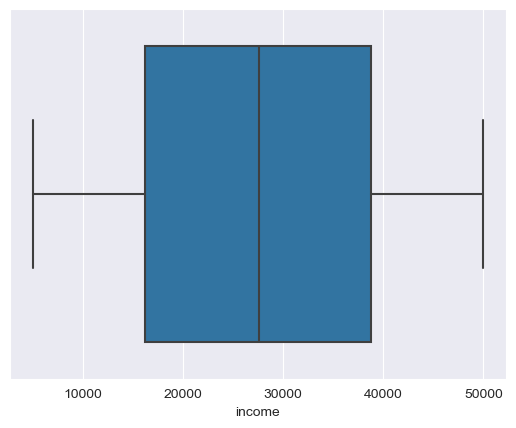

In [198]:
# draw box plot to check outliers
sns.set_style("darkgrid",{'axes.grid' : True})
sns.boxplot(x=df['income'], orient='h')

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='income', ylabel='Count'>

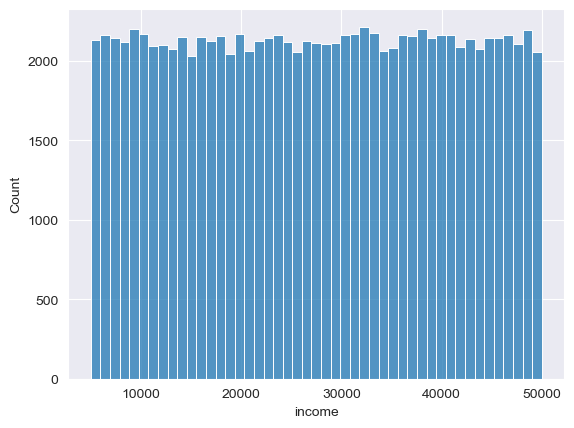

In [199]:
sns.histplot(df['income'])

In [200]:
Q1 = df['income'].quantile(0.25)
Q3 = df['income'].quantile(0.75)
IQR = Q3 - Q1
lower_thresh = Q1 - 1.5*IQR
upper_thresh = Q3 + 1.5*IQR
Q1, Q3, lower_thresh, upper_thresh

(16271.75, 38747.25, -17441.5, 72460.5)

##### for 'purchase_amount'

<Axes: xlabel='purchase_amount'>

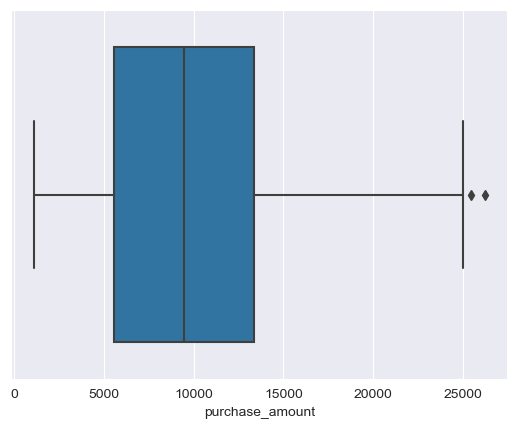

In [201]:
# draw box plot to check outliers
sns.set_style("darkgrid",{'axes.grid' : True})
sns.boxplot(x=df['purchase_amount'], orient='h')

In [202]:
Q1 = df['purchase_amount'].quantile(0.25)
Q3 = df['purchase_amount'].quantile(0.75)
IQR = Q3 - Q1
lower_thresh = Q1 - 1.5*IQR
upper_thresh = Q3 + 1.5*IQR
Q1, Q3, lower_thresh, upper_thresh

(5583.0, 13350.0, -6067.5, 25000.5)

In [203]:
df['purchase_amount'].min( )
df['purchase_amount'].max( )

26204.0

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

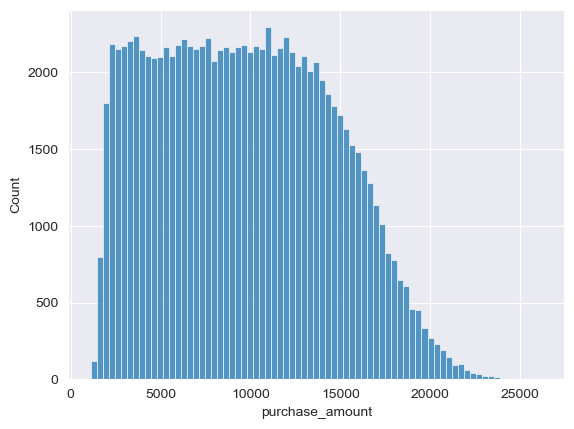

In [204]:
sns.histplot(df['purchase_amount'])

In [205]:
# Based on the above calculation, we will remove samples that have "purchase_amount" above 21000 (>21000) as outliers 
# since they‘re extremely high
df.drop(df[df['purchase_amount'] > 21000].index, inplace=True)
df.shape

(99523, 12)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

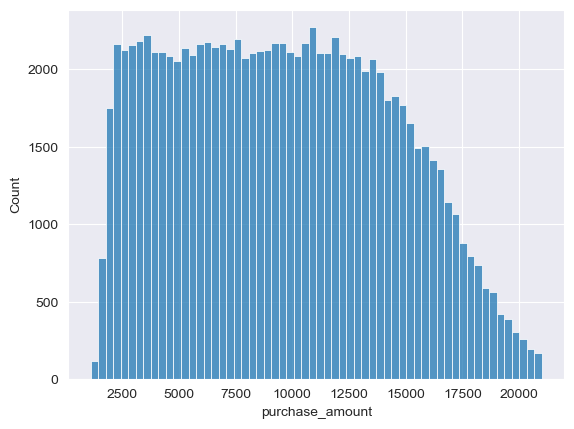

In [206]:
# check the current distribution
sns.histplot(df['purchase_amount'])

### Data transformation
In this part, we will move forward to do data transformation mainly for target variable and numerical data.

#### Transform Target Variable

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='satisfaction_score', ylabel='Count'>

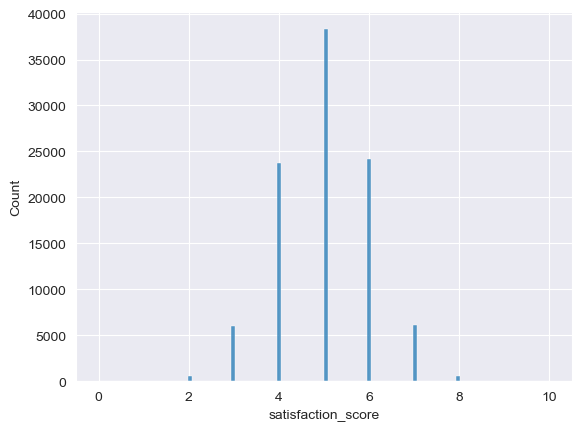

In [207]:
sns.histplot(df['satisfaction_score'])

In [208]:
# We took 5 as a thershold, when satisfaction_score>5, it's considered as satisfied, when <5 it's considered as unsatisfied
conditions = [df['satisfaction_score'] < 5, df['satisfaction_score'] >= 5]
values = ['unsatisfied', 'satisfied']

# Use numpy.where() to set values based on conditions
df['satisfaction_category'] = np.where(conditions[0], values[0], np.where(conditions[1], values[1], np.nan))
df['satisfaction_category'].head(30)

0       satisfied
1       satisfied
2       satisfied
3       satisfied
4       satisfied
5       satisfied
6       satisfied
8       satisfied
9       satisfied
10      satisfied
11      satisfied
12      satisfied
13      satisfied
14    unsatisfied
15      satisfied
17    unsatisfied
18      satisfied
19      satisfied
20      satisfied
21      satisfied
22      satisfied
23    unsatisfied
24      satisfied
25      satisfied
26      satisfied
27      satisfied
28      satisfied
29    unsatisfied
30      satisfied
31    unsatisfied
Name: satisfaction_category, dtype: object

#### Normalize numerical data

#####  Normalize “income”

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='income', ylabel='Count'>

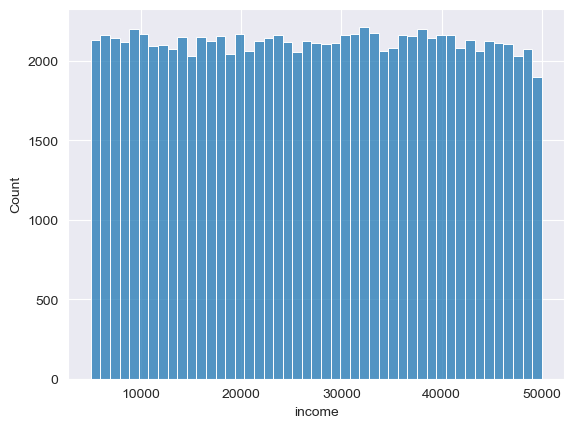

In [209]:
# check the distribution of the "income" before normalization
sns.histplot(df['income'])

In [210]:
# normalize income
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
df['income'] = scaler.fit_transform(df[['income']].values)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='income', ylabel='Count'>

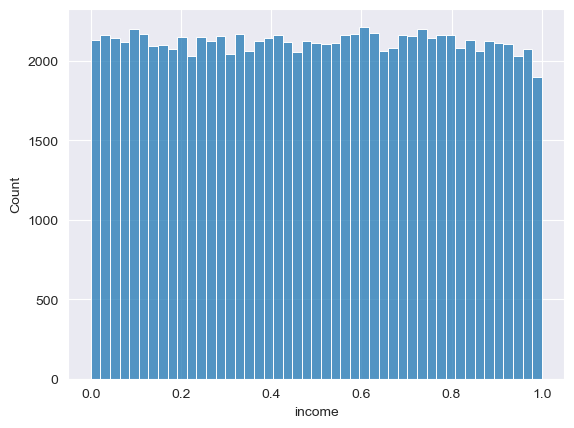

In [211]:
# check the distribution of the "income" after normalization
sns.histplot(df['income'] )

##### Normalize “purchase_amount”

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

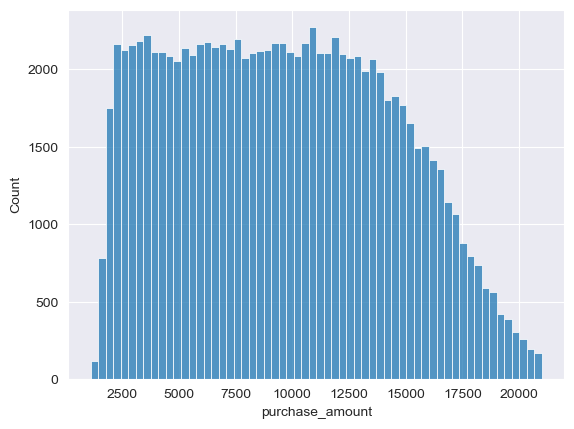

In [212]:
# check the distribution of the "purchase_amount" before normalization
sns.histplot(df['purchase_amount'])

In [213]:
# normalize income
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0,1))
df['purchase_amount'] = scaler.fit_transform(df[['purchase_amount']].values)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='purchase_amount', ylabel='Count'>

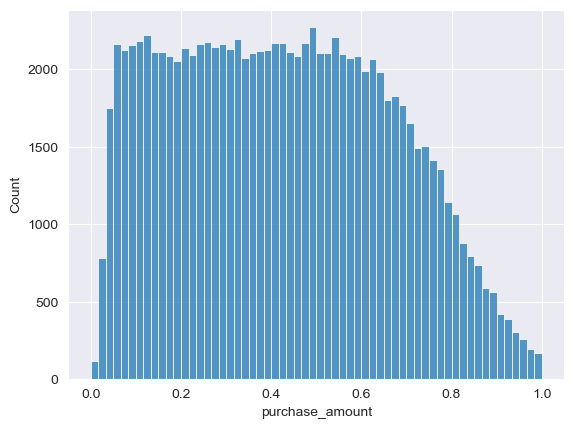

In [214]:
# check the distribution of the "purchase amount" after normalization
sns.histplot(df['purchase_amount'] )

We can see that normalization doesn't change the distribution.

### Feature Engineering

#### Numerical data
- directly use the values

#### Categorical data
- encoding (one-hot/ordinal encoder)

In [215]:
from sklearn.preprocessing import OneHotEncoder

In [216]:
# Initiate one-hot encoder
ohe = OneHotEncoder(handle_unknown='ignore')
ohe_col = ['gender', 'education', 'region', 'loyalty_status', 'product_category', 'promotion_usage', 'purchase_frequency']
ohe.fit(df[ohe_col]) 

# encode the features with the learned categories during the fit process
ohe_features = pd.DataFrame(ohe.transform(df[ohe_col]).toarray())
print(ohe_features)


        0    1    2    3    4    5    6    7    8    9   ...   15   16   17  \
0      0.0  1.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
1      0.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  ...  1.0  0.0  0.0   
2      0.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  1.0  0.0  0.0   
3      0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  0.0  ...  0.0  0.0  1.0   
4      1.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  ...  1.0  0.0  0.0   
...    ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...   
99518  1.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  0.0  0.0  0.0   
99519  0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  0.0  ...  0.0  0.0  0.0   
99520  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  1.0  0.0  0.0   
99521  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  0.0  0.0  0.0   
99522  1.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  ...  0.0  0.0  0.0   

        18   19   20   21   22   23   24  
0      0

In [217]:
# rename columns so we can analyze them later
col_names = []
for i in range(len(ohe_col)):
    for j in ohe.categories_[i]:
        col_names.append(ohe_col[i] + '_' + str(j))

names_dict = {i:col_names[i] for i in range(len(col_names))}
ohe_features.rename(columns=names_dict, inplace=True)
ohe_features

,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,region_South,region_West,...,product_category_Clothing,product_category_Electronics,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare
0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99518,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
99519,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
99520,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
99521,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0


### Additional Analysis

#### Check the colinearity

In [218]:
# set the size of the heatmap.
#plt.figure(figsize=(11, 11))

# Create the heatmap using Seaborn and adjust the font size of annotations\
# df_heat = df[[ohe_features,'income','purchase_amount']]
# heatmap = sns.heatmap(df_heat.corr(), vmin=-1, vmax=1, cmap='BrBG',annot=True)

# Set the title
# heatmap.set_title('Correlation Heatmap', fontdict={'fontsize':30}, pad=14);

## Supervised Learning

In this part, we're going to apply supervised learning models to the dataset. We want to conduct a classfication task to see if and how the features explain the customer's satisfaction.
We would use tree-based models in this part, mainly decision-tree classifier. It's suitable for a binary classification task and it's easy to understand.

### Create train-test split

In [219]:
# Create feature matrix X by concatenating numeric and OHE feature matrix

# Reset indices of df and ohe_features
df.reset_index(drop=True, inplace=True)
ohe_features.reset_index(drop=True, inplace=True)

# Concatenate the DataFrames
df_X = pd.concat([df[['income', 'purchase_amount']], ohe_features], axis=1)

df_X .head(10)

,income,purchase_amount,gender_Female,gender_Male,education_Bachelor,education_College,education_HighSchool,education_Masters,region_East,region_North,...,product_category_Clothing,product_category_Electronics,product_category_Food,product_category_Health,product_category_Home,promotion_usage_0,promotion_usage_1,purchase_frequency_frequent,purchase_frequency_occasional,purchase_frequency_rare
0,0.792933,0.861764,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.229267,0.172997,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.752200,0.538458,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.145956,0.149907,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,0.932267,0.934001,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
5,0.052156,0.085719,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6,0.072556,0.109412,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
7,0.314533,0.236481,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
8,0.437022,0.385382,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
9,0.864356,0.756577,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [220]:
df_X.shape

(99523, 27)

In [221]:
# Create target variable
target = 'satisfaction_category'
df_y = df[[target]]
df_y.head(10)
df_y.shape

(99523, 1)

In [222]:
from sklearn.model_selection import train_test_split

# Create split with Sklearn
df_X_train, df_X_test, df_y_train, df_y_test  = train_test_split(df_X, df_y, test_size = 0.3,random_state = 42)

# View the training and testing feature matrix 
df_X_train.shape, df_X_test.shape

((69666, 27), (29857, 27))

### Decision Tree

#### train and test the decision tree classifier

In [223]:
# Create a DecisionTreeClassifier 
# Please set criterion = "entropy" and random_state = 42, and keep all the other parameters with the default value.
from sklearn import tree
dt_clf = tree.DecisionTreeClassifier(criterion='entropy', random_state=42)

In [224]:
dt_clf.fit(df_X_train, df_y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [225]:
float("{:.3f}".format(dt_clf.score(df_X_test, df_y_test)))

0.572

In [226]:
# Plot the fitted DecisionTreeClassifier. 
# import graphviz
dtc_data = tree.export_graphviz(dt_clf, out_file=None,
                                feature_names=df_X_train.columns,
                                class_names=None,
                                filled=True, rounded=True,
                                special_characters=True)

graph = graphviz.Source(dtc_data)
graph.render("decision_tree_classifier", format='png', cleanup=True, view=True)

##### Explore the parameter

We can see that using the default hyperparameter, the decision tree is too complicated compared to the data complexity and the accuracy score is relatively low. We want to improve the model performance a little manually.

In [227]:
# max_depth=100
dt_clf2 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42,max_depth=100)
dt_clf2.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf2.score(df_X_test, df_y_test)))

0.573

In [244]:
# setting max_depth=10
dt_clf3 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42,max_depth=10)

dt_clf3.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf2.score(df_X_test, df_y_test)))

0.695

In [228]:
# setting min_samples_split=3
dt_clf4 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_split=3)

dt_clf4.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf3.score(df_X_test, df_y_test)))

0.579

In [245]:
# setting min_samples_split=10
dt_clf5 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_split=10)

dt_clf5.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf3.score(df_X_test, df_y_test)))

0.579

In [246]:
# setting min_samples_leaf=50
dt_clf6 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_leaf=100)

dt_clf6.fit(df_X_train, df_y_train)
float("{:.3f}".format(dt_clf7.score(df_X_test, df_y_test)))

0.697

In [230]:
# combine the settings
dt_clf7 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=10, min_samples_split=3, min_samples_leaf=100)

# fit the model
dt_clf7.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_clf7.score(df_X_test, df_y_test)))

0.697

#### model evaluation
Use the best model we just explored and evaluate it.

In [248]:
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, auc

# Obtain predictions from the model
predictions = dt_clf7.predict(df_X_test)

# Calculate accuracy
accuracy = accuracy_score(df_y_test, predictions)
print(accuracy)

0.6967880229092005


The accuracy score shows the model get around 70% overall correctness in prediction, which is acceptable. 

In [232]:
from sklearn.metrics import confusion_matrix
confusion_matrix(df_y_test, predictions)

array([[20793,    29],
       [ 9024,    11]])

In [256]:
from sklearn.metrics import precision_score, recall_score

# Convert string labels to numeric labels in predictions
predictions_numeric = [1 if label == 'satisfied' else 0 for label in predictions]

# Convert df_y_test to numeric labels
df_y_test_numeric = df_y_test.replace({'satisfied': 1, 'unsatisfied': 0})

# Calculate precision
precision = precision_score(df_y_test_numeric, predictions_numeric)
print(precision)

# Calculate recall
recall = recall_score(df_y_test_numeric, predictions_numeric)
print(recall)

0.6973538585370762
0.9986072423398329


We can see that the model gets lower precision score than recall, meaning it gets more false positives than false negatives. The current model is more inclined to predict the classification as "satisfied".

We also want to focus on the general performance of the model, not only for one class or one category.

In [243]:
from sklearn.metrics import f1_score,roc_auc_score

# Calculate F1 score
f1 = f1_score(df_y_test_numeric, predictions_numeric)
print(f1)

# Calculate AUC-ROC
auc_roc = roc_auc_score(df_y_test_numeric, predictions_numeric)
print(auc_roc)

0.8212247477240863
0.49991236494412783


F1 provides a balance between precision and recall.
AUC-ROC evaluates how well a binary classification model discriminates between positive and negative instances across different threshold values, which is important for our model since it's binary classification task. However, the 0.5 AUC-ROC leaves a space for improvement.

We may need further actions such as parameter tuning to align the data complexity and model complexity.

#### error analysis

In [255]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
confusion_matrix(df_y_test, predictions)

array([[20793,    29],
       [ 9024,    11]])

We can see that the model suffers most from the false positives. It's inclined to predict the uncertain targets as "satisfied".

#### feature importance

In [163]:
# extract feature names of best performing model
features = dt_clf7.feature_names_in_
# extract feature importance
importance = np.round(dt_clf7.feature_importances_,2)

# Create pandas dataframe of feature and correpsonding importance
df_importance = pd.DataFrame([features, importance]).T
df_importance.rename(columns={0: 'feature', 1:'importance'}, inplace=True)

# Sort descendingly based on importance
df_importance.sort_values(['importance'], ascending=False, inplace=True)

# Show dataframe
df_importance.reset_index(drop=True)

,feature,importance
0,purchase_amount,0.36
1,income,0.3
2,product_category_Food,0.03
3,gender_Male,0.03
4,product_category_Electronics,0.03
5,education_College,0.03
6,region_West,0.02
7,promotion_usage_1,0.02
8,loyalty_status_Silver,0.02
9,loyalty_status_Gold,0.02


The most obvious top 2 features are purchase_amount and income.
Purchase amount has a positive correlation with satisfaction. The higher the purchase_amount is, the customer is more possible to be satisfied. This correlation can be considered as if the customer is more satisfied, they are more likely to buy more.
Income also a positive correlation with satisfaction. The higher the income is, the customer is more possible to be satisfied. It makes sense because when someone's income low, they would be very catious about what they buy and quality of money-spending. Otherwise, high-income individuals may be more tolerant with their purchase experiences.

#### Strengths and Weaknesses

Strengths:
Handling Non-linear Relationships: Decision trees can capture non-linear relationships between features and the target variable.
Interpretability: Decision trees are easy to understand and interpret, making them suitable for explaining the decision-making process.
Non-parametric: Decision trees make no assumptions about the distribution of the data or the relationship between features, which can be advantageous in certain scenarios.

Weaknesses:
Overfitting: Decision trees tend to overfit the training data, especially if they are allowed to grow deep or if the dataset is noisy. As we can see, the accuracy score on test data is 0.7.
Instability: Small variations in the data can lead to significantly different decision trees, making the model unstable. That could be why the AUC-ROC score is low.
Limited Expressiveness: Decision trees may struggle to capture complex relationships in the data compared to more sophisticated models like random forests.

The potential strategies could conlude try different models and Hyperparameter Tuning.

### Random Forest

In [169]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators = 150, criterion = 'entropy', random_state = 42)

# train RFC
rf_clf.fit(df_X_train, df_y_train)

# evaluate the random forest classifier on test set 
float("{:.3f}".format(rf_clf.score(df_X_test, df_y_test)))

/var/folders/d_/y18dh801041_kbnwl118jfyr0000gn/T/ipykernel_59792/288440957.py:6: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  rf_clf.fit(df_X_train, df_y_train)


0.631

In [251]:
# extract feature names of initial model
features = rf_clf.feature_names_in_
# extract feature importance
importance = np.round(rf_clf.feature_importances_,2)

# Create pandas dataframe of features and correpsonding importance
df_importance = pd.DataFrame([features, importance]).T
df_importance.rename(columns={0: 'feature', 1:'importance'}, inplace=True)

# Sort descendingly based on importance
df_importance.sort_values(['importance'], ascending=False, inplace=True)

# Show dataframe
df_importance.reset_index(drop=True)

,feature,importance
0,income,0.4
1,purchase_amount,0.4
2,loyalty_status_Silver,0.01
3,purchase_frequency_occasional,0.01
4,purchase_frequency_frequent,0.01
5,promotion_usage_1,0.01
6,promotion_usage_0,0.01
7,product_category_Home,0.01
8,product_category_Health,0.01
9,product_category_Food,0.01


The most obvious top 2 features are still purchase_amount and income and their importance even rise a little bit.